In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [4]:
diabetes = load_diabetes()

X = diabetes.data
y = diabetes.target

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Features:", diabetes.feature_names)

Dataset shape: (442, 10)
Target shape: (442,)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


In [5]:
df = pd.DataFrame(X, columns=diabetes.feature_names)
df["target"] = y

print(df.head())

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 353
Testing samples : 89


In [7]:
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("linear", LinearRegression())
])

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_r2 = r2_score(y_test, y_pred_linear)

print("Linear Regression")
print("-----------------")
print("MSE:", linear_mse)
print("R-squared:", linear_r2)

Linear Regression
-----------------
MSE: 2900.1936284934823
R-squared: 0.45260276297191926


In [8]:
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

ridge_params = {
    "ridge__alpha": [0.01, 0.1, 1, 10, 100]
}

ridge_grid = GridSearchCV(
    ridge_pipeline,
    ridge_params,
    cv=5,
    scoring="neg_mean_squared_error"
)

ridge_grid.fit(X_train, y_train)

best_ridge = ridge_grid.best_estimator_

y_pred_ridge = best_ridge.predict(X_test)

ridge_mse = mean_squared_error(y_test, y_pred_ridge)
ridge_r2 = r2_score(y_test, y_pred_ridge)

print("Ridge Regression")
print("----------------")
print("Best Alpha:", ridge_grid.best_params_["ridge__alpha"])
print("MSE:", ridge_mse)
print("R-squared:", ridge_r2)

Ridge Regression
----------------
Best Alpha: 10
MSE: 2875.7787184218428
R-squared: 0.4572109567780849


In [9]:
lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(max_iter=10000))
])

lasso_params = {
    "lasso__alpha": [0.001, 0.01, 0.1, 1, 10]
}

lasso_grid = GridSearchCV(
    lasso_pipeline,
    lasso_params,
    cv=5,
    scoring="neg_mean_squared_error"
)

lasso_grid.fit(X_train, y_train)

best_lasso = lasso_grid.best_estimator_

y_pred_lasso = best_lasso.predict(X_test)

lasso_mse = mean_squared_error(y_test, y_pred_lasso)
lasso_r2 = r2_score(y_test, y_pred_lasso)

print("Lasso Regression")
print("----------------")
print("Best Alpha:", lasso_grid.best_params_["lasso__alpha"])
print("MSE:", lasso_mse)
print("R-squared:", lasso_r2)

Lasso Regression
----------------
Best Alpha: 1
MSE: 2824.568094049959
R-squared: 0.46687670944102466


In [10]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "MSE": [
        linear_mse,
        ridge_mse,
        lasso_mse
    ],
    "R-squared": [
        linear_r2,
        ridge_r2,
        lasso_r2
    ]
})

print(results.to_string(index=False))

            Model         MSE  R-squared
Linear Regression 2900.193628   0.452603
 Ridge Regression 2875.778718   0.457211
 Lasso Regression 2824.568094   0.466877


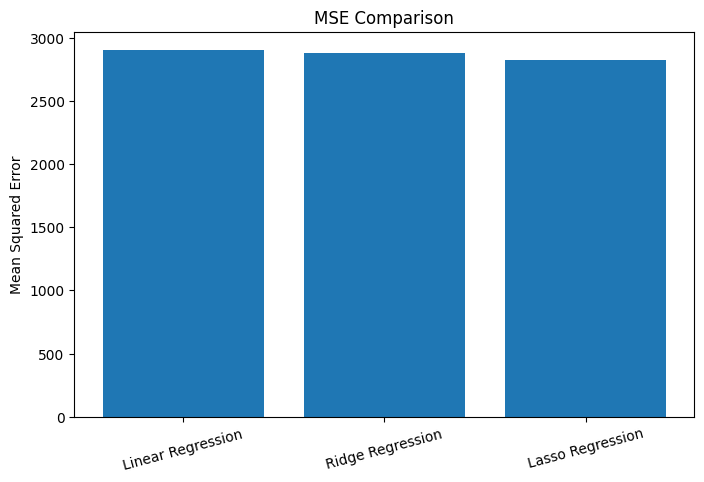

In [11]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["MSE"]
)

plt.ylabel("Mean Squared Error")
plt.title("MSE Comparison")

plt.xticks(rotation=15)
plt.show()

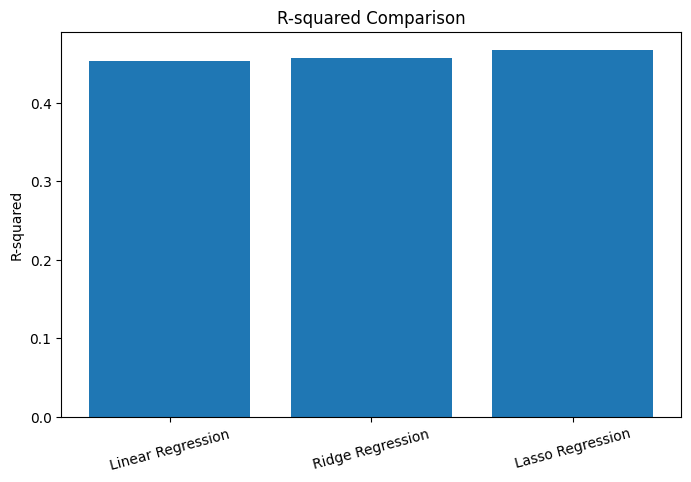

In [12]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["R-squared"]
)

plt.ylabel("R-squared")
plt.title("R-squared Comparison")

plt.xticks(rotation=15)
plt.show()

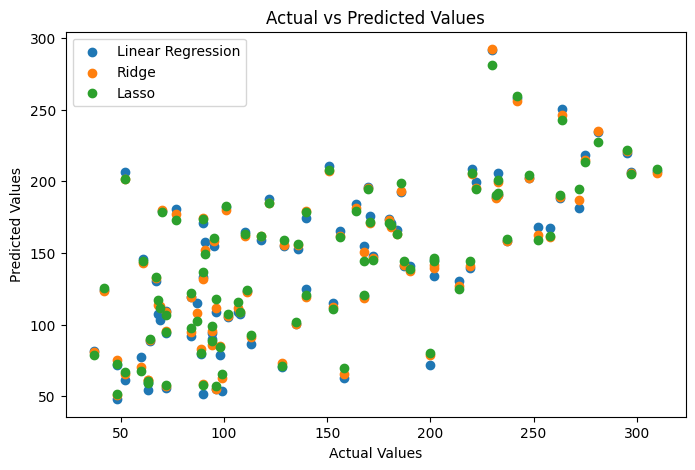

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_linear, label="Linear Regression")
plt.scatter(y_test, y_pred_ridge, label="Ridge")
plt.scatter(y_test, y_pred_lasso, label="Lasso")

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values")

plt.legend()
plt.show()

In [14]:
print("FINAL CONCLUSION")

best_mse_model = results.loc[results["MSE"].idxmin(), "Model"]
best_r2_model = results.loc[results["R-squared"].idxmax(), "Model"]

print("Best model based on MSE:", best_mse_model)
print("Best model based on R-squared:", best_r2_model)

print("\nRidge uses L2 regularization.")
print("Lasso uses L1 regularization.")
print("Linear Regression has no regularization.")

========== FINAL CONCLUSION ==========
Best model based on MSE: Lasso Regression
Best model based on R-squared: Lasso Regression

Ridge uses L2 regularization.
Lasso uses L1 regularization.
Linear Regression has no regularization.
